# Urban Mobility: Exploring Bike-Sharing Demand

This project is my opportunity to put the skills from the [Google Data Analysis with Python Specialization](https://www.coursera.org/specializations/google-data-analysis-with-python) into practice.

I’m using the UCI Bike Sharing Dataset to explore how and when people use a bike-sharing service. Along the way, I’ll work through the full analysis in one Jupyter Notebook: loading the data, checking and cleaning it, creating date and time features, analysing patterns, and building visualisations.

## Questions I want to explore

1. How many rentals come from casual users compared with registered users?
2. Which hours are busiest, and which are quietest?
3. Does rental activity look different on weekdays and weekends?
4. How are weather conditions related to rental demand?
5. Are there unusually high or low hourly rental counts worth investigating?

**Dataset:** UCI Bike Sharing Dataset, using the hourly records in `hour.csv` from 2011–2012.

To follow the analysis, run the notebook from top to bottom. It expects `hour.csv` in the project's `data/` folder. The original dataset also includes `day.csv`, although this notebook focuses on the hourly data.


## 1. Getting set up

First, I’ll import the libraries I’ll use throughout the project.

- **Python** helps me organise the steps and work with the data.
- **NumPy** is useful for numerical calculations and working with arrays.
- **Pandas** makes it easier to load, inspect, clean and analyse tabular data.
- **Datetime** tools help me work with dates, hours and days of the week.
- **Matplotlib and Seaborn** help me turn the results into charts.

I’m keeping the work in this notebook so the process is easy to follow, from the first look at the data through to the final findings.


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
CHART_DIR = PROJECT_DIR / "outputs"

sns.set_theme(style="whitegrid", palette="deep", context="notebook")

print("Project root:", PROJECT_DIR)
print("Data directory exists:", DATA_DIR.exists())
print("Chart output directory:", CHART_DIR)

Project root: c:\Users\siddh\OneDrive\Desktop\Code\urban-mobility-data-analysis
Data directory exists: True
Chart output directory: c:\Users\siddh\OneDrive\Desktop\Code\urban-mobility-data-analysis\outputs


## 2. Loading the dataset

I’ll start with `hour.csv`. It contains one record for each hour, which makes it a good fit for looking at daily routines and changes in demand throughout the day.

When I load the file, I’ll ask Pandas to read `dteday` as a date rather than leaving it as plain text. That will make the date-based analysis much easier later on.


In [2]:
hour_file = DATA_DIR / "hour.csv"

if not hour_file.exists():
    raise FileNotFoundError(
        f"Could not find {hour_file}. Place hour.csv inside the project's data/ directory."
    )

df = pd.read_csv(hour_file, parse_dates=["dteday"])

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 3. Getting to know the data

Before analysing anything, I want to understand what I’m working with.

These Pandas methods give me a useful first overview:

- `shape` tells me how many rows and columns the dataset has.
- `info()` shows the column names, data types and non-missing values.
- `describe()` gives a quick statistical summary of the numerical columns.
- `isna().sum()` helps me check for missing values.

One detail to keep in mind: `temp`, `atemp`, `hum` and `windspeed` are normalised measurements in the original dataset. They are not direct readings in degrees Celsius or percentages.


In [3]:
print("Dataset dimensions:", df.shape)
print("\nColumn information:")
df.info()

print("\nMissing values by column:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Dataset dimensions: (17379, 17)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  

,missing_values
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Duplicate rows: 0

Descriptive statistics:


,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


## 4. Cleaning and checking the data

Now that I’ve had a first look at the dataset, I’ll check for missing values and duplicate rows. I’ll remove exact duplicates if there are any, but I won’t fill missing values without first deciding what would make sense for each column.

There’s also a useful consistency check built into this dataset: casual rentals plus registered rentals should equal the total rental count.

In other words:

`casual + registered = cnt`

If a row doesn’t satisfy that relationship, I’ll flag it for a closer look.


In [4]:
df = df.copy()

missing_before = int(df.isna().sum().sum())
duplicates_before = int(df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Missing values before cleaning:", missing_before)
print("Duplicate rows before cleaning:", duplicates_before)
print("Shape after duplicate removal:", df.shape)

rental_check = df["casual"].add(df["registered"]).eq(df["cnt"])
valid_records = int(rental_check.sum())
invalid_records = int((~rental_check).sum())

negative_rentals = int(
    df[["casual", "registered", "cnt"]].lt(0).to_numpy().sum()
)

print("\nRental count validation")
print("Valid records:", valid_records)
print("Invalid records:", invalid_records)
print("Negative rental values:", negative_rentals)

print("\nDate range:", df["dteday"].min(), "to", df["dteday"].max())
print("Observed hours:", sorted(df["hr"].unique().tolist()))
print("Observed seasons:", sorted(df["season"].unique().tolist()))


Missing values before cleaning: 0
Duplicate rows before cleaning: 0
Shape after duplicate removal: (17379, 17)

Rental count validation
Valid records: 17379
Invalid records: 0
Negative rental values: 0

Date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00
Observed hours: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
Observed seasons: [1, 2, 3, 4]


## 5. Working with dates and times

The dataset stores the date (`dteday`) and hour (`hr`) in separate columns. I’ll combine them into a single timestamp and create a few extra columns, such as the year, month name and day name.

I’ll also add a weekend indicator. In this dataset, `weekday` is encoded with **0 for Sunday** and **6 for Saturday**, so those are the values I’ll use to identify weekends.


In [5]:
df["year"] = df["dteday"].dt.year
df["month"] = df["dteday"].dt.month
df["month_name"] = df["dteday"].dt.month_name()
df["day_name"] = df["dteday"].dt.day_name()

df["datetime"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
df["is_weekend"] = df["weekday"].isin([0, 6])

display(
    df[
        ["dteday", "hr", "datetime", "year", "month_name", "day_name", "is_weekend"]
    ].head(10)
)


,dteday,hr,datetime,year,month_name,day_name,is_weekend
0,2011-01-01,0,2011-01-01 00:00:00,2011,January,Saturday,True
1,2011-01-01,1,2011-01-01 01:00:00,2011,January,Saturday,True
2,2011-01-01,2,2011-01-01 02:00:00,2011,January,Saturday,True
3,2011-01-01,3,2011-01-01 03:00:00,2011,January,Saturday,True
4,2011-01-01,4,2011-01-01 04:00:00,2011,January,Saturday,True
5,2011-01-01,5,2011-01-01 05:00:00,2011,January,Saturday,True
6,2011-01-01,6,2011-01-01 06:00:00,2011,January,Saturday,True
7,2011-01-01,7,2011-01-01 07:00:00,2011,January,Saturday,True
8,2011-01-01,8,2011-01-01 08:00:00,2011,January,Saturday,True
9,2011-01-01,9,2011-01-01 09:00:00,2011,January,Saturday,True


## 6. Exploring rental numbers with NumPy and Pandas

### 6.1 Casual and registered users

First, I want to see how rentals are split between casual and registered users.

I’ll add up the rentals for each group across the dataset and calculate each group's percentage of the total. This gives a simple picture of which type of user accounts for most of the recorded activity.


In [6]:
casual_total = int(df["casual"].sum())
registered_total = int(df["registered"].sum())
total_rentals = casual_total + registered_total

user_totals = np.array([casual_total, registered_total], dtype=np.int64)
user_percentages = user_totals / user_totals.sum() * 100

print(f"Casual rentals: {casual_total:,} ({user_percentages[0]:.2f}%)")
print(f"Registered rentals: {registered_total:,} ({user_percentages[1]:.2f}%)")
print(f"Total rentals: {total_rentals:,}")
print(f"Percentage check: {user_percentages.sum():.2f}%")


Casual rentals: 620,017 (18.83%)
Registered rentals: 2,672,662 (81.17%)
Total rentals: 3,292,679
Percentage check: 100.00%


### 6.2 A closer look at rental counts

Next, I’ll summarise the hourly rental counts (`cnt`) using a few common statistics: mean, median, standard deviation, minimum, maximum and quartiles.

I’m using NumPy here to practise working directly with numerical data. One small detail matters: NumPy's `std()` uses the population standard deviation by default (`ddof=0`), while Pandas' `.std()` uses the sample version by default (`ddof=1`). I’ll set `ddof=0` so the calculation is explicit.


In [7]:
rentals = df["cnt"].to_numpy()

rental_statistics = {
    "mean": np.mean(rentals),
    "median": np.median(rentals),
    "population_std": np.std(rentals, ddof=0),
    "minimum": np.min(rentals),
    "maximum": np.max(rentals),
    "25th_percentile": np.percentile(rentals, 25),
    "50th_percentile": np.percentile(rentals, 50),
    "75th_percentile": np.percentile(rentals, 75),
}

display(pd.Series(rental_statistics, name="value").to_frame())


,value
mean,189.463088
median,142.000000
population_std,181.382380
minimum,1.000000
maximum,977.000000
25th_percentile,40.000000
50th_percentile,142.000000
75th_percentile,281.000000


### 6.3 How demand changes by hour

To see when people tend to rent bikes, I’ll group the records by hour and calculate the average, median and maximum number of rentals for each hour.

I’ll use the average to identify the busiest and quietest hours. That gives a better sense of a typical pattern than choosing an hour based on one unusually high observation.


In [8]:
hourly_demand = (
    df.groupby("hr")["cnt"]
    .agg(mean="mean", median="median", max="max", observations="count")
    .round(2)
)

busiest_hour = int(hourly_demand["mean"].idxmax())
quietest_hour = int(hourly_demand["mean"].idxmin())

display(hourly_demand)
print(f"Busiest average hour: {busiest_hour:02d}:00 ({hourly_demand.loc[busiest_hour, 'mean']:.2f} rentals)")
print(f"Quietest average hour: {quietest_hour:02d}:00 ({hourly_demand.loc[quietest_hour, 'mean']:.2f} rentals)")


,mean,median,max,observations
hr,,,,
0,53.90,40.0,283,726
1,33.38,20.0,168,724
2,22.87,11.0,132,715
3,11.73,6.0,79,697
4,6.35,6.0,28,697
5,19.89,19.0,66,717
6,76.04,76.0,213,725
7,212.06,208.0,596,727
8,359.01,385.0,839,727


Busiest average hour: 17:00 (461.45 rentals)
Quietest average hour: 04:00 (6.35 rentals)


### 6.4 Weekdays and weekends

Do people use the bikes differently during the working week and at the weekend?

I’ll compare the average and median hourly rental counts for the two groups. I’ll include the number of records in each group as well, since the dataset does not contain the same number of working-day and weekend observations.

This is a descriptive comparison. It can show us a difference in the data, but it doesn’t tell us on its own whether that difference is statistically significant.


In [9]:
day_comparison = (
    df.groupby("is_weekend")["cnt"]
    .agg(mean="mean", median="median", std="std", count="count")
    .rename(index={False: "Weekday", True: "Weekend"})
    .round(2)
)

display(day_comparison)

weekday_mean = day_comparison.loc["Weekday", "mean"]
weekend_mean = day_comparison.loc["Weekend", "mean"]
difference_pct = (weekday_mean - weekend_mean) / weekend_mean * 100

print(f"Weekday average is {difference_pct:.2f}% higher than weekend average.")


,mean,median,std,count
is_weekend,,,,
Weekday,191.74,150.0,184.18,12365
Weekend,183.85,122.0,174.20,5014


Weekday average is 4.29% higher than weekend average.


## 7. Looking at weather correlations

I’ll now look at how temperature, feels-like temperature, humidity and wind speed are related to the total number of rentals.

The correlation coefficient describes the direction and strength of a **linear relationship**:
- A positive value means the two variables tend to increase together.
- A negative value means one tends to decrease as the other increases.
- A value near zero suggests little linear relationship.

Correlation doesn’t mean that one variable causes the other. I’ll also pay attention to the relationship between `temp` and `atemp`, since those two measurements may contain very similar information.


In [10]:
weather_columns = ["temp", "atemp", "hum", "windspeed", "cnt"]
correlation_matrix = df[weather_columns].corr()

display(correlation_matrix.round(3))

print("Correlation with total rentals:")
display(
    correlation_matrix["cnt"]
    .drop("cnt")
    .sort_values(ascending=False)
    .round(3)
)


,temp,atemp,hum,windspeed,cnt
temp,1.000,0.988,-0.070,-0.023,0.405
atemp,0.988,1.000,-0.052,-0.062,0.401
hum,-0.070,-0.052,1.000,-0.290,-0.323
windspeed,-0.023,-0.062,-0.290,1.000,0.093
cnt,0.405,0.401,-0.323,0.093,1.000


Correlation with total rentals:


temp         0.405
atemp        0.401
windspeed    0.093
hum         -0.323
Name: cnt, dtype: float64

## 8. Finding potential outliers with the IQR method

Some hours may have much higher rental counts than most others. To flag unusually high or low values, I’ll use the interquartile range (IQR).

The IQR is the difference between the 75th percentile (Q3) and the 25th percentile (Q1). The usual rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

I won’t automatically remove the flagged records. A busy hour could be a genuine event or demand peak, rather than a mistake in the data. The purpose here is to identify records worth investigating.


In [11]:
q1 = df["cnt"].quantile(0.25)
q3 = df["cnt"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = df["cnt"].lt(lower_bound) | df["cnt"].gt(upper_bound)
outliers = df.loc[outlier_mask].copy()

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"Potential outlier records: {len(outliers):,} ({len(outliers) / len(df) * 100:.2f}%)")

display(outliers[["dteday", "hr", "weathersit", "temp", "hum", "cnt"]].head())


Q1: 40.00
Q3: 281.00
IQR: 241.00
Lower bound: -321.50
Upper bound: 642.50
Potential outlier records: 505 (2.91%)


,dteday,hr,weathersit,temp,hum,cnt
5536,2011-08-23,14,1,0.72,0.30,651
10358,2012-03-12,17,2,0.62,0.38,644
10359,2012-03-12,18,2,0.60,0.43,712
10382,2012-03-13,17,1,0.70,0.37,676
10383,2012-03-13,18,1,0.70,0.34,734


## 9. Visualising what the data shows

Numbers and summary tables are useful, but charts make patterns easier to spot. In this section, I’ll use Matplotlib and Seaborn to create a small set of visualisations.

Each chart will also be saved in `outputs/`. That way, I can reuse the images in the project README without having to recreate them separately.


### 9.1 Average rentals by hour

This line chart shows how average rental demand changes over a 24-hour period. I’ll highlight the busiest and quietest hours so the main pattern is easy to pick out.


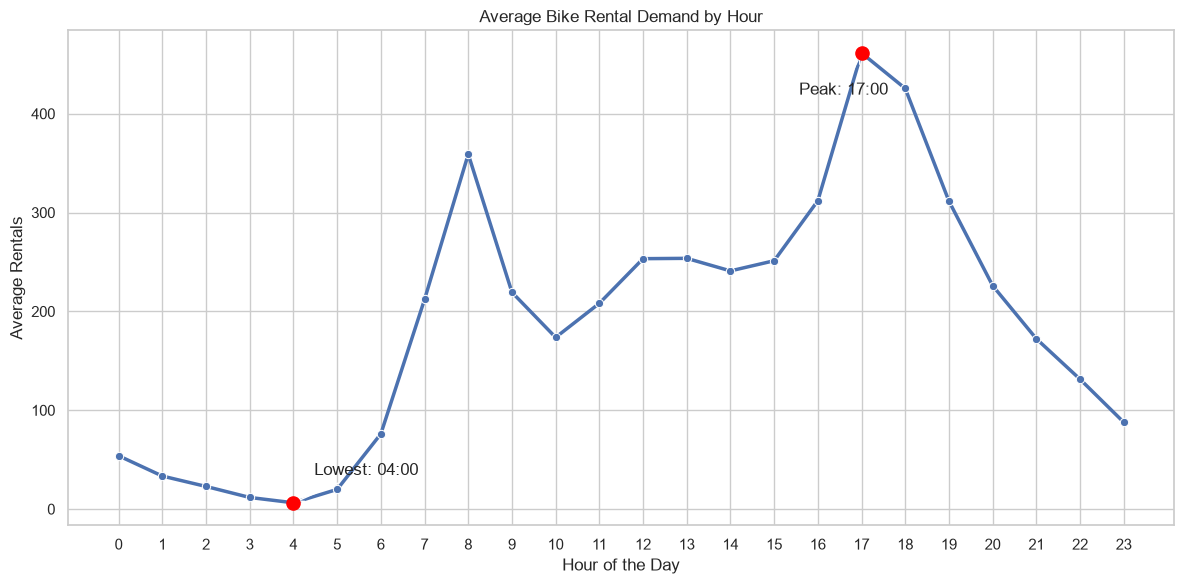

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand["mean"],
    marker="o",
    linewidth=2.5,
    ax=ax
)

ax.scatter(
    [busiest_hour, quietest_hour],
    [hourly_demand.loc[busiest_hour, "mean"], hourly_demand.loc[quietest_hour, "mean"]],
    color="red",
    s=90,
    zorder=5
)

ax.annotate(
    f"Peak: {busiest_hour:02d}:00",
    xy=(busiest_hour, hourly_demand.loc[busiest_hour, "mean"]),
    xytext=(-45, -30),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)
ax.annotate(
    f"Lowest: {quietest_hour:02d}:00",
    xy=(quietest_hour, hourly_demand.loc[quietest_hour, "mean"]),
    xytext=(15, 20),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)

ax.set(
    title="Average Bike Rental Demand by Hour",
    xlabel="Hour of the Day",
    ylabel="Average Rentals"
)
ax.set_xticks(range(24))
fig.tight_layout()
fig.savefig(CHART_DIR / "hourly_demand.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


### 9.2 Casual and registered rentals

This chart compares the share of rentals made by casual and registered users. It gives a quick visual summary of the user split calculated earlier.


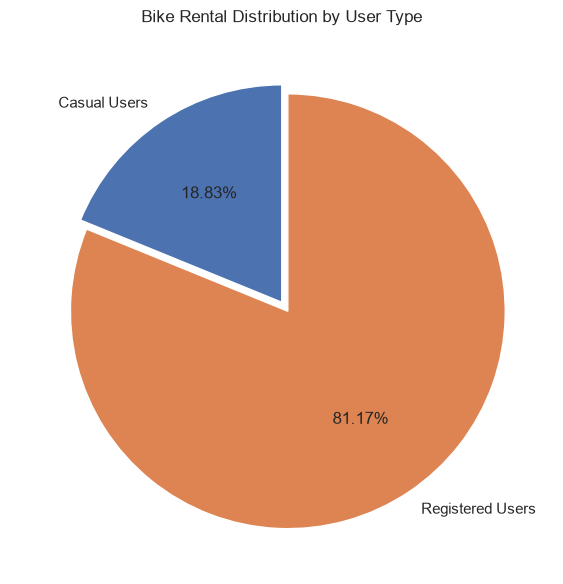

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.pie(
    user_totals,
    labels=["Casual Users", "Registered Users"],
    autopct="%1.2f%%",
    startangle=90,
    explode=(0, 0.05)
)
ax.set_title("Bike Rental Distribution by User Type")
fig.tight_layout()
fig.savefig(CHART_DIR / "user_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


### 9.3 Weekday and weekend demand

Here I’ll compare the average hourly rental counts for weekdays and weekends. I’ve added the values to the bars so the size of the difference is clear without having to estimate it from the axis.


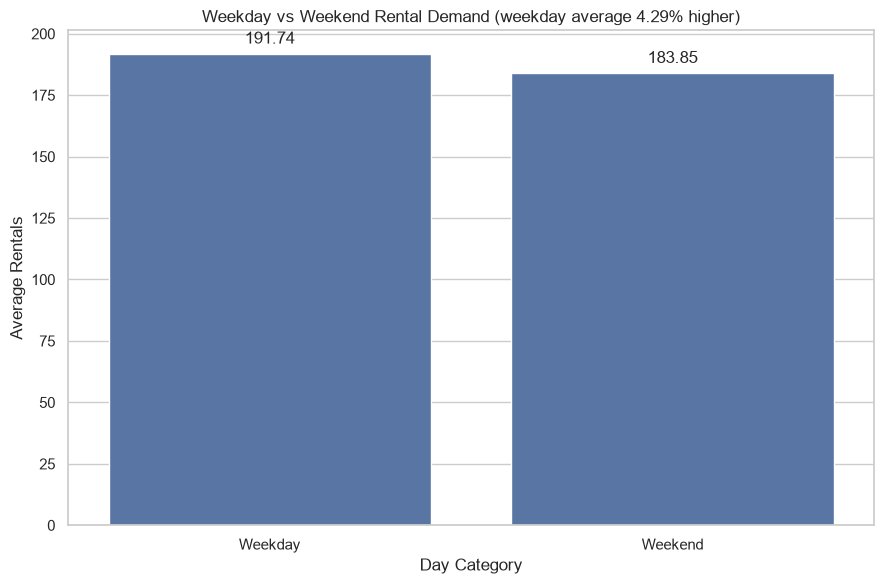

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))

plot_data = day_comparison.reset_index(names="day_category")
sns.barplot(data=plot_data, x="day_category", y="mean", ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=5)

ax.set(
    title=f"Weekday vs Weekend Rental Demand (weekday average {difference_pct:.2f}% higher)",
    xlabel="Day Category",
    ylabel="Average Rentals"
)
fig.tight_layout()
fig.savefig(CHART_DIR / "weekday_vs_weekend.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


### 9.4 Weather and rental correlations

The heatmap brings the correlation values together in one view. The colours help show the direction of each relationship, while the numbers give the exact coefficients.


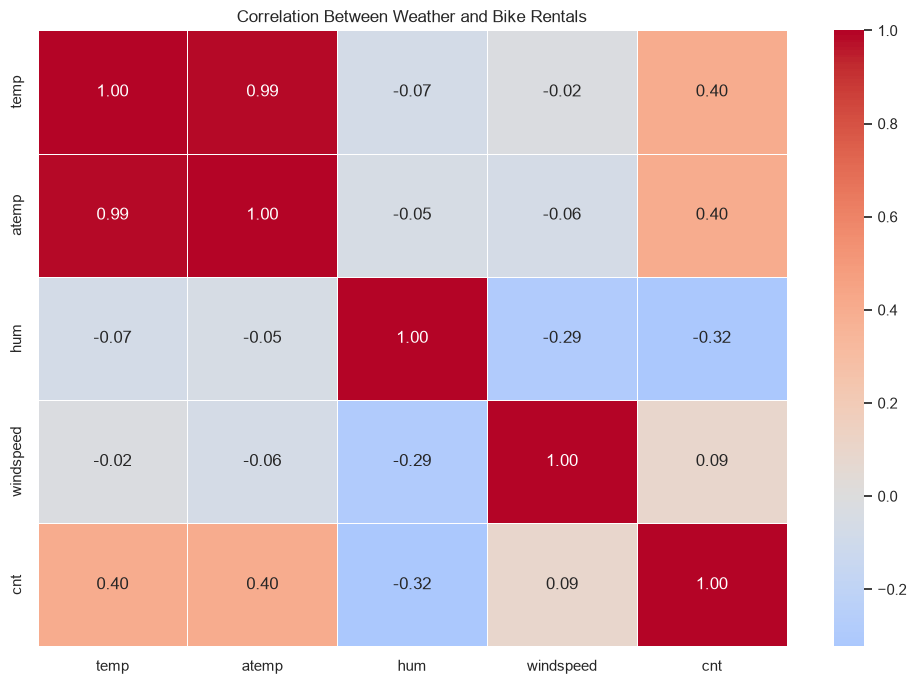

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    ax=ax
)

ax.set_title("Correlation Between Weather and Bike Rentals")
fig.tight_layout()
fig.savefig(CHART_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


### 9.5 Rental demand by day and hour

This heatmap breaks the hourly pattern down by day of the week. I’m using it to look for differences between working days and weekends that might be hidden by the overall averages.


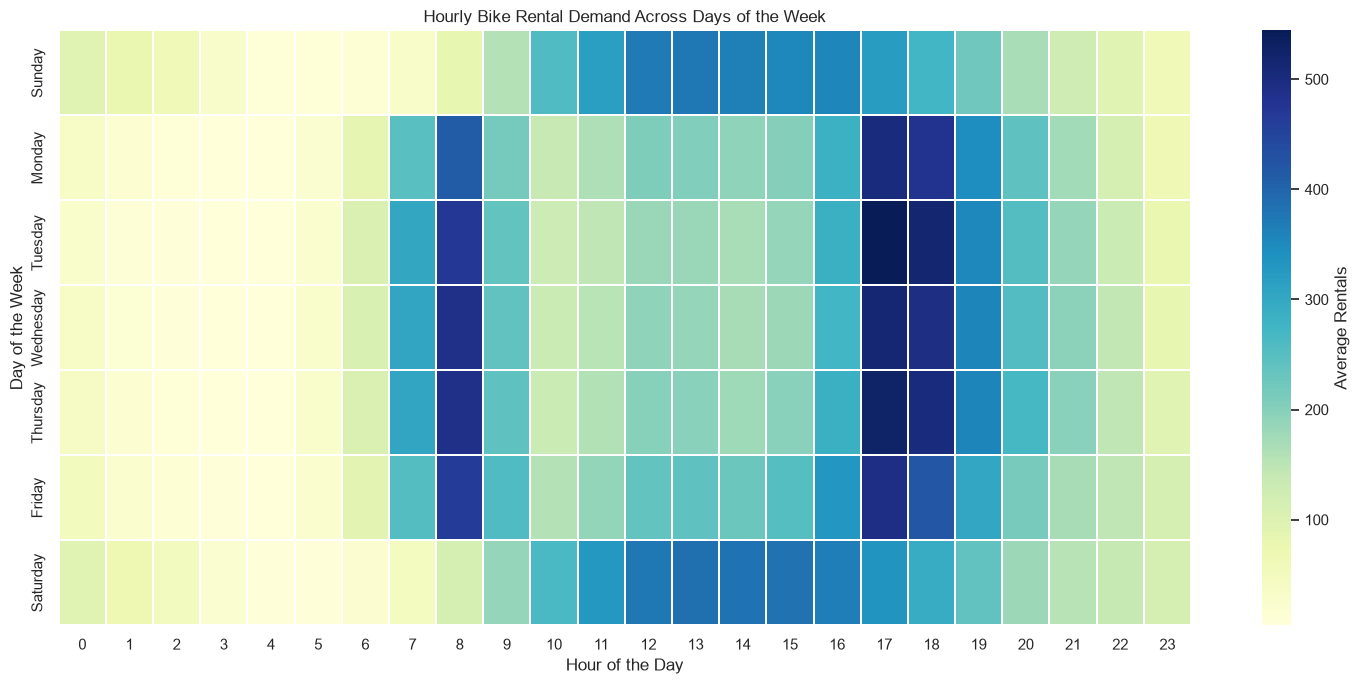

In [16]:
weekday_names = [
    "Sunday", "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday"
]

weekday_hourly = (
    df.groupby(["weekday", "hr"])["cnt"]
    .mean()
    .unstack()
    .reindex(range(7))
)
weekday_hourly.index = weekday_names

fig, ax = plt.subplots(figsize=(15, 7))

sns.heatmap(
    weekday_hourly,
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Average Rentals"},
    ax=ax
)

ax.set(
    title="Hourly Bike Rental Demand Across Days of the Week",
    xlabel="Hour of the Day",
    ylabel="Day of the Week"
)
fig.tight_layout()
fig.savefig(CHART_DIR / "weekday_hour_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


## 10. What I found

After looking through the summaries and charts, a few patterns stand out:

1. **User mix:** Registered users account for a larger share of rentals than casual users.
2. **Time of day:** Demand rises during the morning and reaches a stronger peak in the evening. The quietest period is overnight.
3. **Weekdays and weekends:** Average hourly demand is a little higher on weekdays, while the heatmap gives a more detailed view of how the daily patterns differ.
4. **Weather:** Temperature has a moderate positive correlation with rentals, while humidity has a moderate negative correlation. These are relationships in the data, not evidence of cause and effect.
5. **Potential outliers:** The IQR method identifies some unusually high hourly counts. I’ve kept these records because they may reflect genuine periods of high demand.

### A few limitations to keep in mind

- The records cover 2011–2012, so they may not reflect how people use bike-sharing services today.
- Correlation does not prove causation.
- The weather variables are normalised in the source dataset.
- This is an exploratory analysis, not a statistical significance test or a demand-forecasting model.
- The data comes from one bike-sharing system, so the patterns may not apply to every city or service.


## 11. Running the notebook again

The notebook saves five charts in `outputs`:

- `hourly_demand.png`
- `user_distribution.png`
- `weekday_vs_weekend.png`
- `correlation_heatmap.png`
- `weekday_hour_heatmap.png`

To reproduce the analysis on your machine:

1. Install the libraries listed in `requirements.txt`.
2. Place the original `hour.csv` file in the `data/` folder.
3. Open this notebook in Jupyter.
4. Run the cells in order, from top to bottom.

## 12. Dataset credit

The data used in this project comes from:

Fanaee-T, H. (2013). **Bike Sharing Dataset**. UCI Machine Learning Repository.  
https://doi.org/10.24432/C5W894

The dataset is distributed under the Creative Commons Attribution 4.0 International (CC BY 4.0) licence. Please keep the attribution with the data if you share it.

## 13. Use of AI as a learning assistant

I used AI as a learning assistant while working through this project and the concepts from the Google Data Analysis with Python Specialization.

It helped me understand unfamiliar concepts, think through analysis steps, troubleshoot code errors, and improve how I explained the results. I used it as a guide when I got stuck, rather than treating its responses as finished work to copy without review.

I ran the code, checked the outputs, and worked through the analysis as I built the notebook. This process helped me practise applying Python, NumPy, Pandas, datetime operations, Matplotlib and Seaborn to a real dataset.

AI assistance was part of my learning process; the purpose of the project was to build my own understanding by applying the course material.

---

This project is my way of putting the concepts from the **Google Data Analysis with Python Specialization** into practice using a real dataset.
